# Exercise: How many nodes?

Can a neural net tell **EDM** from **rap**? Do more nodes help?

Let's revisit the Spotify data from the lecture 13 exercise and compare logistic regression, a random forest, and neural nets with 2, 10, and 50 hidden nodes.

## Setup

In [1]:
library('tidymodels')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

── Attaching packages ───────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ──────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Learn how to get started at https://www.tidymodels.org/start/


## The data

Each row is one song. `genre` is `rap` or `edm`. The predictors are `danceability` and `tempo`.

In [2]:
songs <- read.csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-01-21/spotify_songs.csv')

songs <- songs |>
    filter(playlist_genre %in% c('edm', 'rap')) |>
    distinct(track_id, .keep_all = TRUE) |>
    mutate(genre = factor(playlist_genre, levels = c('rap', 'edm'))) |>
    select(track_name, track_artist, genre, danceability, tempo)

songs |> count(genre)

  genre n   
1 rap   5486
2 edm   5437

## Setup for the models

Run these cells. Do not change them.

- Split the songs in half: `train` and `test`.
- `train_small` has only 100 songs from `train`.
- `fit_nn()` fits a neural net with `h` hidden nodes. It normalizes the predictors first.
- `accuracy_of()` finds the share of songs a model gets right.

In [3]:
set.seed(512)
split <- initial_split(songs, prop = 0.5, strata = genre)
train <- training(split)
test  <- testing(split)

set.seed(3)
train_small <- train |> slice_sample(n = 100)

In [4]:
rec <- recipe(genre ~ danceability + tempo, data = songs) |>
    step_normalize(all_predictors())

fit_nn <- function(h, data) {
    set.seed(1)
    workflow() |>
        add_recipe(rec) |>
        add_model(
            mlp(hidden_units = h, epochs = 1000, penalty = 0) |>
                set_mode('classification') |>
                set_engine('nnet', MaxNWts = 5000)
        ) |>
        fit(data = data)
}

accuracy_of <- function(fit, data) {
    pred <- predict(fit, new_data = data, type = 'class')$.pred_class
    mean(pred == data$genre)
}

## 1. Small data: 100 songs

`compare_models()` fits five models: logistic regression, a random forest, and neural nets with 2, 10, and 50 hidden nodes. It returns two accuracies for each model:

- `train_accuracy`: on the songs used to fit the model.
- `test_accuracy`: on the `test` songs, which the model has not seen.

Run the cell. It uses only `train_small`, which has 100 songs.

In [5]:
compare_models <- function(train_data) {
    set.seed(512)
    fits <- list(
        logistic = logistic_reg() |> fit(genre ~ danceability + tempo, data = train_data),
        forest   = rand_forest(trees = 200) |> set_mode('classification') |> set_engine('ranger') |>
                       fit(genre ~ danceability + tempo, data = train_data),
        `nn 2`   = fit_nn(2, train_data),
        `nn 10`  = fit_nn(10, train_data),
        `nn 50`  = fit_nn(50, train_data)
    )

    tibble(
        model = names(fits),
        train_accuracy = map_dbl(fits, accuracy_of, data = train_data),
        test_accuracy  = map_dbl(fits, accuracy_of, data = test)
    )
}

results_small = compare_models(train_small)

results_small

         model    train_accuracy test_accuracy
logistic logistic 0.57           0.6054559    
forest   forest   0.91           0.7995240    
nn 2     nn 2     0.86           0.8061150    
nn 10    nn 10    0.92           0.7724277    
nn 50    nn 50    0.99           0.7158550    

**Check:** `nn 50` should be right for about 0.99 of the training songs.

- Which model is best on the **training** songs? Which is best on the **test** songs?
- What happens to the test accuracy of the nets as the number of nodes goes up?
- A net with 50 hidden nodes learns 201 numbers. How many songs did we give it?

**Answers:**

- On the **training** songs, `nn 50` is best (0.99), followed by `nn 10` (0.92) and the forest (0.91). On the **test** songs, `nn 2` is best (0.806), just ahead of the forest (0.800).
- Test accuracy goes **down** as nodes go up: 0.806 for `nn 2`, 0.772 for `nn 10`, and 0.716 for `nn 50`. The bigger nets fit the training songs better but do worse on new songs. That is overfitting.
- We gave it only **100 songs**, fewer than the 201 numbers it learns. With more parameters than data points, the net can basically memorize the training set, noise included.

## 2. Chart the output

Pick a visualization for the output and make the chart below. Write the code by hand or prompt it with `OpenCode`.

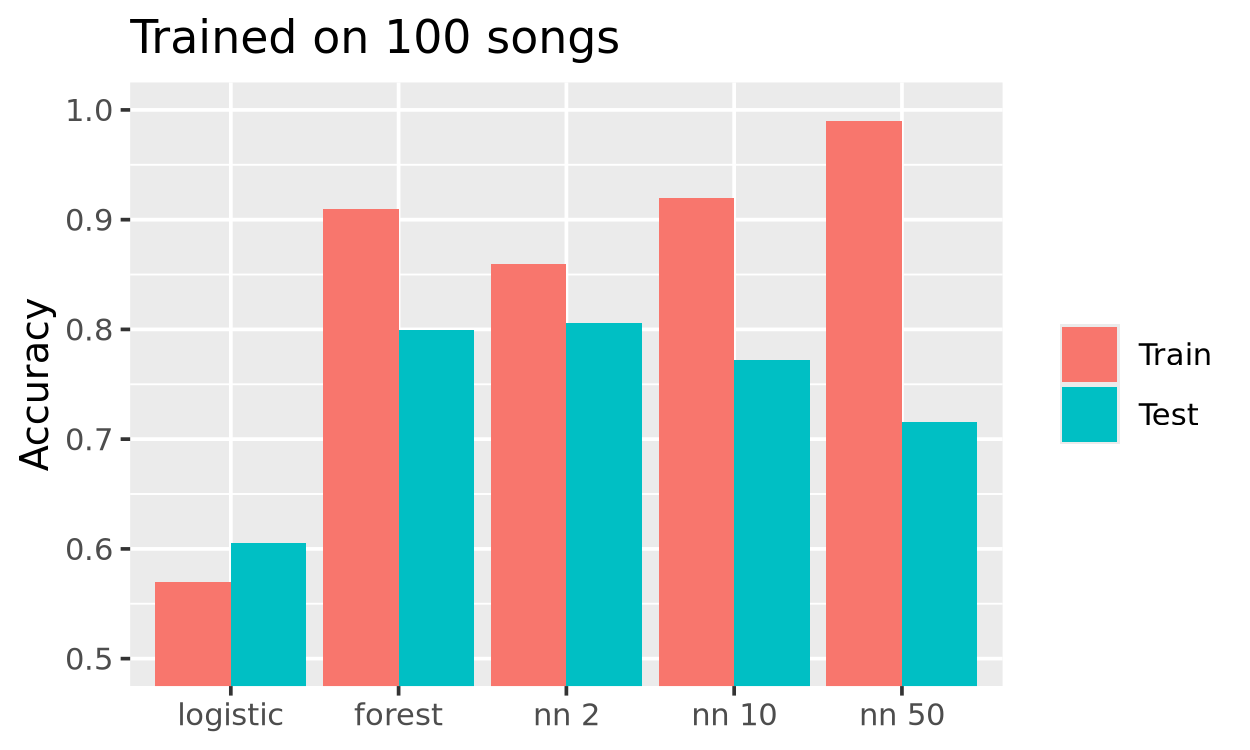

In [8]:
plot_results <- function(results, title) {
    results |>
        pivot_longer(c(train_accuracy, test_accuracy), names_to = 'data', values_to = 'accuracy') |>
        mutate(
            model = factor(model, levels = c('logistic', 'forest', 'nn 2', 'nn 10', 'nn 50')),
            data  = factor(data, levels = c('train_accuracy', 'test_accuracy'), labels = c('Train', 'Test'))
        ) |>
        ggplot(aes(x = model, y = accuracy, fill = data)) +
        geom_col(position = 'dodge') +
        coord_cartesian(ylim = c(0.5, 1)) +
        labs(x = NULL, y = 'Accuracy', fill = NULL, title = title)
}

plot_results(results_small, 'Trained on 100 songs')

## 3. More data

Run `compare_models()` again, with all of `train` (about 5,500 songs).

In [9]:
results_all <- compare_models(train)

results_all

         model    train_accuracy test_accuracy
logistic logistic 0.6033693      0.6023435    
forest   forest   0.9366416      0.8196631    
nn 2     nn 2     0.8090093      0.8149030    
nn 10    nn 10    0.8170665      0.8218601    
nn 50    nn 50    0.8331807      0.8147199    

**Check:** the nets should now be close to the forest, at about 0.82 on the test songs.

- Is `nn 50` still much worse than `nn 2`? Do more nodes help now?
- Logistic regression is stuck at about 0.60. Why? (Think about the stripe in the lecture 13 exercise.)

**Answers:**

- No. With all of `train`, `nn 50` (0.815) is about the same as `nn 2` (0.815), and `nn 10` is a hair better (0.822). More nodes no longer hurt, but they barely help either: all three nets land near the forest (0.820). With ~5,500 songs, 201 parameters cannot memorize the data, so train and test accuracy are now close (about 0.81 to 0.83 for every net).
- Logistic regression draws a single straight line (a linear boundary) through danceability and tempo. In the lecture 13 exercise, EDM sat in a **stripe** (a narrow band of tempo values, about 125 to 130 BPM, where many EDM songs sit) with rap on both sides. No single straight line can separate a stripe from the areas on both sides of it, so logistic regression stays near the base rate (~0.60). The forest and the nets can carve out curved or boxed regions, so they capture the stripe.

## 4. Plot the results when using all the data

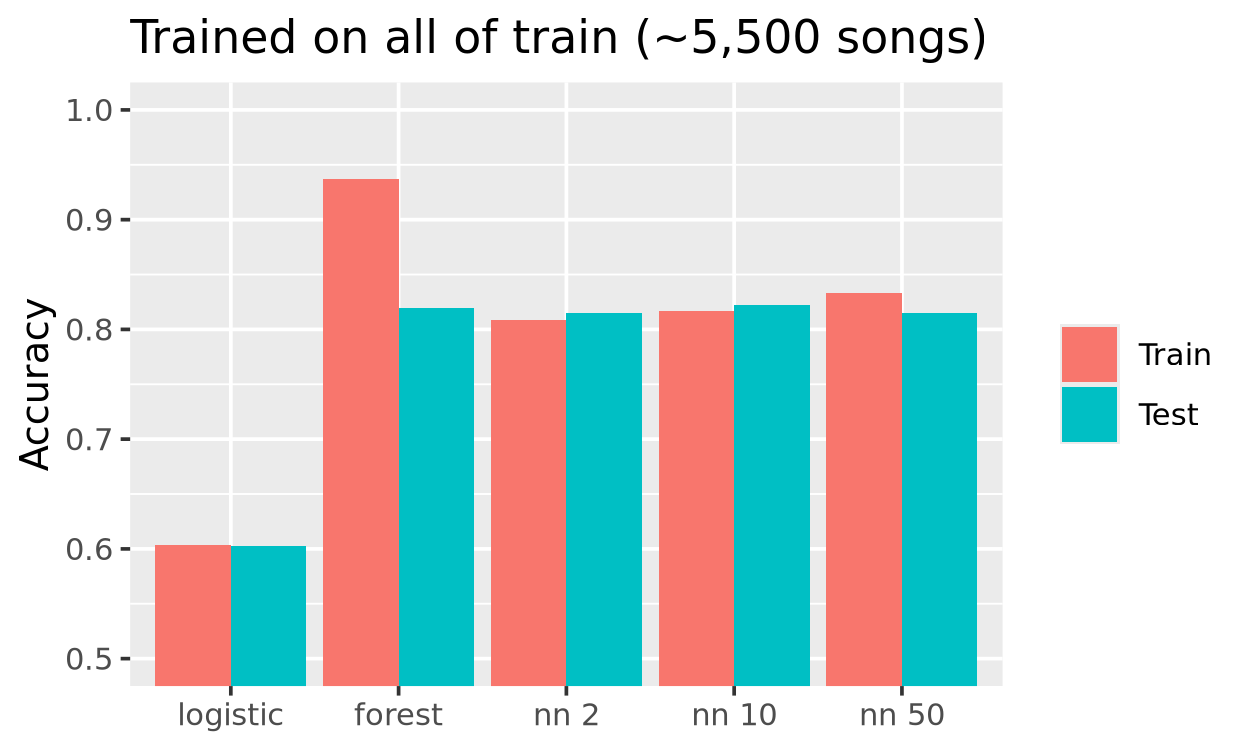

In [10]:
plot_results(results_all, 'Trained on all of train (~5,500 songs)')

## 5. Which model?

You must pick one model for a new playlist with **100 labeled songs**. Which do you pick?

*Your answer:*

I would pick **`nn 2`** (with the random forest a close second). With only 100 songs, `nn 2` had the best test accuracy (0.806) and the smallest gap between train (0.86) and test, so it overfits the least. `nn 10` and `nn 50` overfit badly on 100 songs (test 0.77 and 0.72), and logistic regression cannot capture the tempo stripe (0.61). The forest (0.80) is nearly as good, but `nn 2` is simple, flexible enough for the nonlinear boundary, and holds up best when data is scarce.